In [1]:
from pathlib import Path

DATA_DIR = Path("data/SKAB")
SUBFOLDERS = ["valve1", "valve2", "other"]
ANOMALY_FREE_FILE = DATA_DIR / "anomaly-free" / "anomaly-free.csv"

LABEL_COL = "anomaly"
CHANGEPOINT_COL = "changepoint"  
TIME_COL = "datetime"
# Zvolené okno: 120 s pri vzorkovaní 1 Hz.
# Veľkosť okna je kompromis medzi zachytením dostatočnej časti anomálie
# a časovou lokalizáciou. Vhodnosť overujeme diagnostikou nižšie.
WINDOW_SIZE = 120
# Stride 5 s znamená vysoký prekryv okien; ponechané ako baseline.
WINDOW_STRIDE = 5   
RANDOM_STATE = 42
LABEL_THRESHOLD = 0.3


In [2]:
import pandas as pd
import numpy as np

def load_skab_folder(data_dir: Path, subfolders):
    """Načíta všetky CSV súbory zo SKAB priečinkov a vráti zoznam (df, experiment_id)."""
    experiments = []
    for sub in subfolders:
        folder = data_dir / sub
        if not folder.exists():
            print(f"Priečinok {folder} neexistuje, preskakujem.")
            continue
        for csv_path in sorted(folder.glob("*.csv")):
            df = pd.read_csv(csv_path, sep=";", index_col=TIME_COL, parse_dates=True)
            df["experiment_id"] = f"{sub}/{csv_path.stem}"
            experiments.append(df)
    return experiments

experiments = load_skab_folder(DATA_DIR, SUBFOLDERS)

anomaly_free_df = None
if ANOMALY_FREE_FILE.exists():
    anomaly_free_df = pd.read_csv(ANOMALY_FREE_FILE, sep=";", index_col=TIME_COL, parse_dates=True)
    for col in [LABEL_COL, CHANGEPOINT_COL]:
        if col not in anomaly_free_df.columns:
            anomaly_free_df[col] = 0
    anomaly_free_df["experiment_id"] = "anomaly-free"

print(f"Načítaných {len(experiments)} experimentov s anomáliami.")
if experiments:
    print(experiments[0].head())
    FEATURE_COLS = [c for c in experiments[0].columns
                    if c not in [LABEL_COL, CHANGEPOINT_COL, "experiment_id"]]
    print("\nFeatures:", FEATURE_COLS)


Načítaných 34 experimentov s anomáliami.
                     Accelerometer1RMS  Accelerometer2RMS  Current  Pressure  \
datetime                                                                       
2020-03-09 10:14:33           0.026588           0.040111  1.33020  0.054711   
2020-03-09 10:14:34           0.026170           0.040452  1.35399  0.382638   
2020-03-09 10:14:35           0.026199           0.039419  1.54006  0.710565   
2020-03-09 10:14:36           0.026027           0.039641  1.33458  0.382638   
2020-03-09 10:14:37           0.026290           0.040273  1.07851 -0.273216   

                     Temperature  Thermocouple  Voltage  Volume Flow RateRMS  \
datetime                                                                       
2020-03-09 10:14:33      79.3366       26.0199  233.062                 32.0   
2020-03-09 10:14:34      79.5158       26.0258  236.040                 32.0   
2020-03-09 10:14:35      79.3756       26.0265  251.380                 32.0  

Podiel anomálnych bodov v dátach: 35.35%


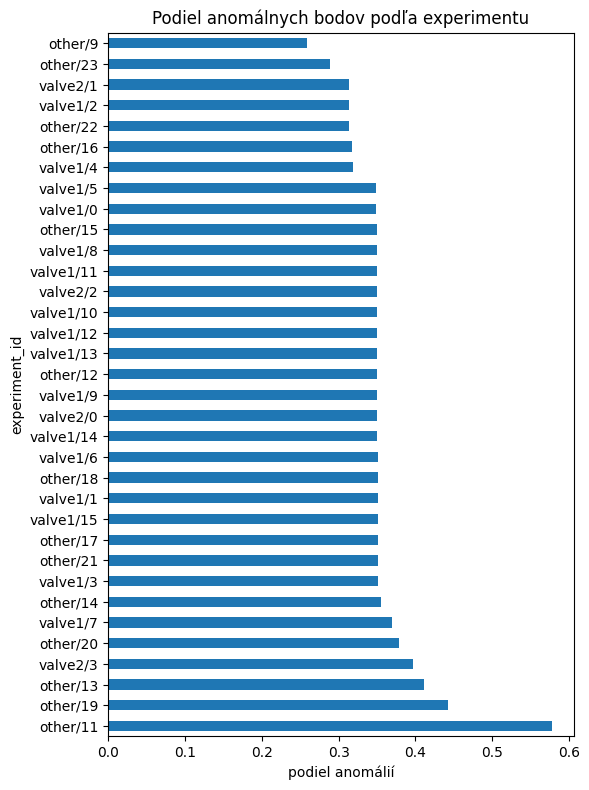

In [3]:
import matplotlib.pyplot as plt

if experiments:
    all_exp = pd.concat(experiments)
    anomaly_ratio = all_exp[LABEL_COL].mean()
    print(f"Podiel anomálnych bodov v dátach: {anomaly_ratio:.2%}")

    counts = all_exp.groupby("experiment_id")[LABEL_COL].mean().sort_values(ascending=False)
    counts.plot(kind="barh", figsize=(6, 8), title="Podiel anomálnych bodov podľa experimentu")
    plt.xlabel("podiel anomálií")
    plt.tight_layout()
    plt.show()


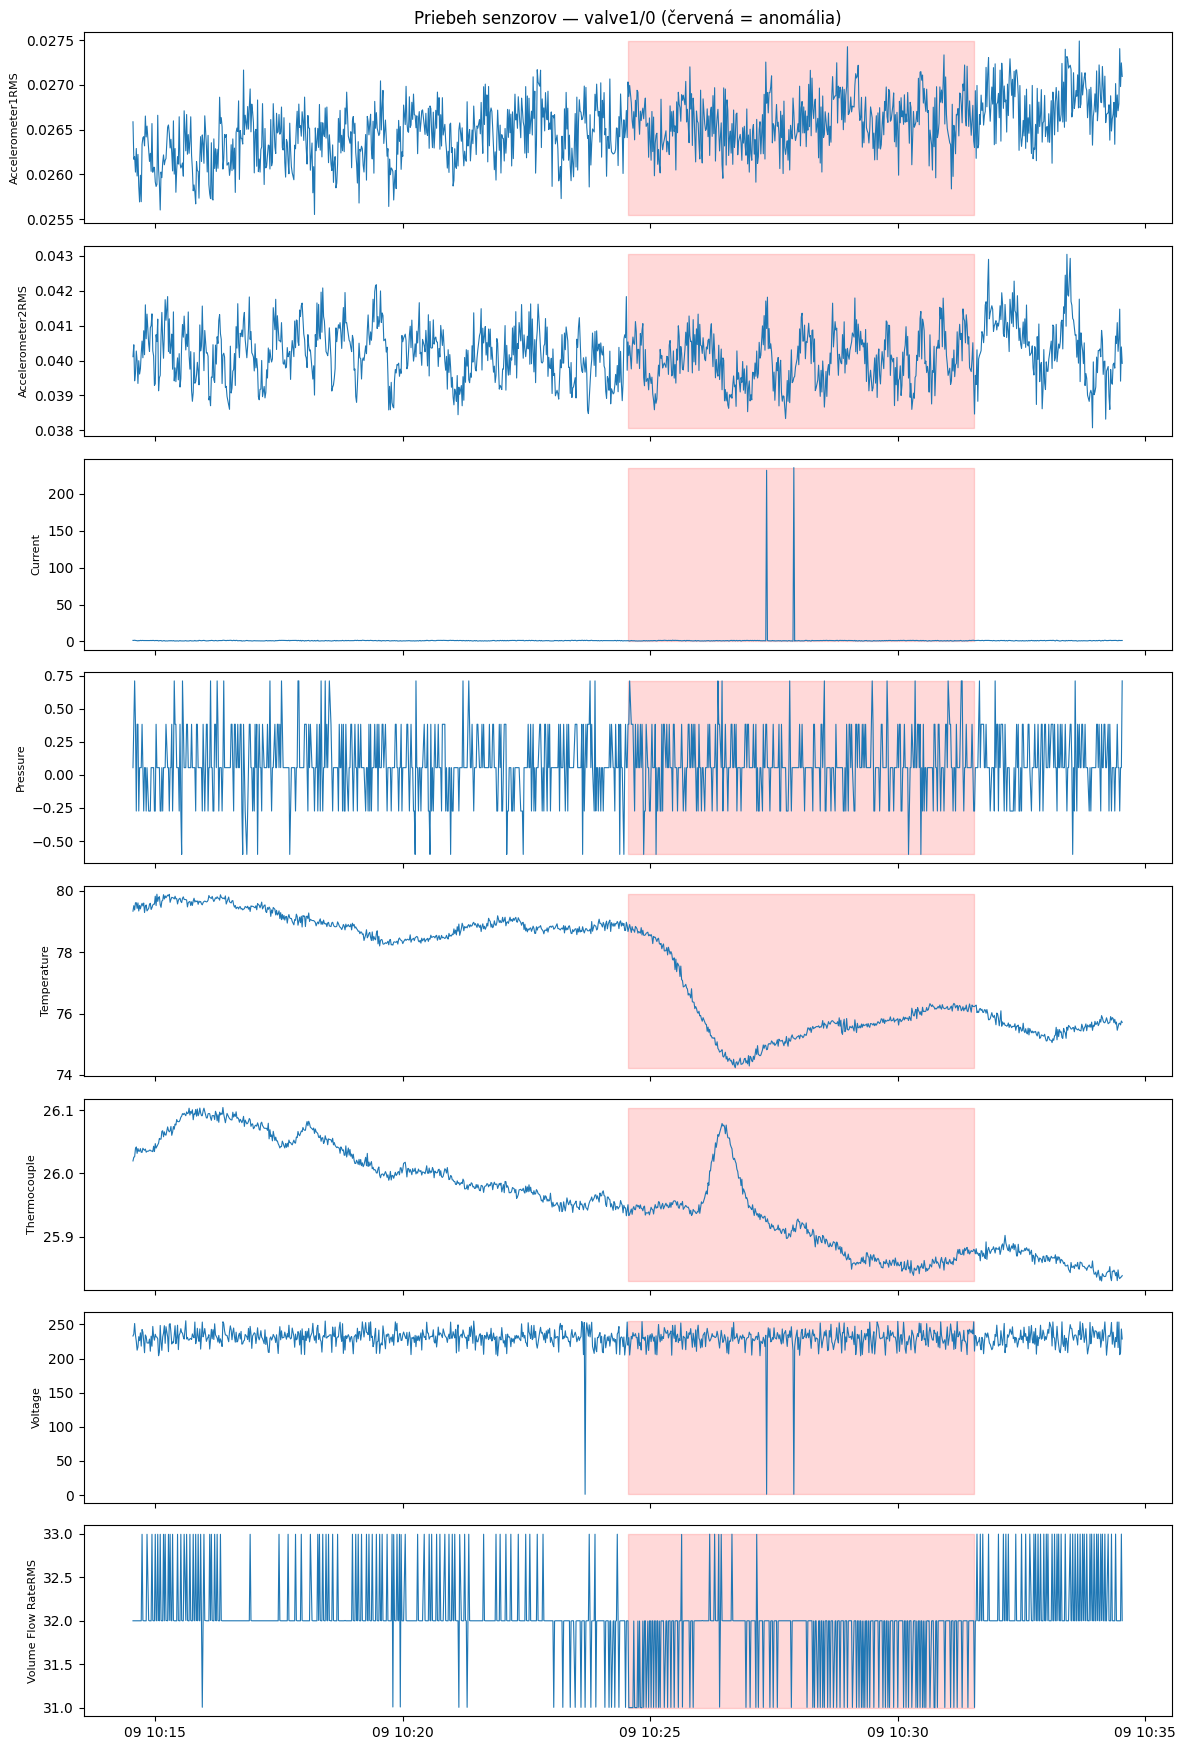

In [4]:
if experiments:
    example = experiments[0]
    fig, axes = plt.subplots(len(FEATURE_COLS), 1, figsize=(12, 2.2 * len(FEATURE_COLS)), sharex=True)
    for ax, col in zip(axes, FEATURE_COLS):
        ax.plot(example.index, example[col], lw=0.8)
        ax.fill_between(example.index, example[col].min(), example[col].max(),
                         where=example[LABEL_COL] == 1, color="red", alpha=0.15)
        ax.set_ylabel(col, fontsize=8)
    axes[0].set_title(f"Priebeh senzorov — {example['experiment_id'].iloc[0]} (červená = anomália)")
    plt.tight_layout()
    plt.show()


In [5]:
def make_windows(df: pd.DataFrame, feature_cols, label_col, window_size, stride):
    values = df[feature_cols].values
    labels = df[label_col].values
    X, y, idx = [], [], []
    for start in range(0, len(df) - window_size + 1, stride):
        end = start + window_size
        X.append(values[start:end].flatten())
        y.append(int(labels[start:end].max()))
        idx.append(df.index[end - 1])
    return np.array(X), np.array(y), idx

def build_dataset(experiment_list, feature_cols, label_col, window_size, stride):
    Xs, ys, ids = [], [], []
    for df in experiment_list:
        X, y, idx = make_windows(df, feature_cols, label_col, window_size, stride)
        Xs.append(X); ys.append(y); ids.extend([df['experiment_id'].iloc[0]] * len(y))
    return np.vstack(Xs), np.concatenate(ys), ids


Diagnostika voľby veľkosti okna:


,window_size_s,n_windows,positive_windows,positive_share,median_anomaly_fraction_positive,mean_anomaly_fraction_positive,positive_windows_lt_25pct_anomaly
0,30,7309,2837,0.390,1.000,0.931,0.033
1,60,7105,3025,0.427,1.000,0.870,0.062
2,120,6697,3393,0.509,1.000,0.770,0.112
3,180,6289,3696,0.589,0.817,0.699,0.140
4,240,5881,3684,0.628,0.738,0.676,0.110


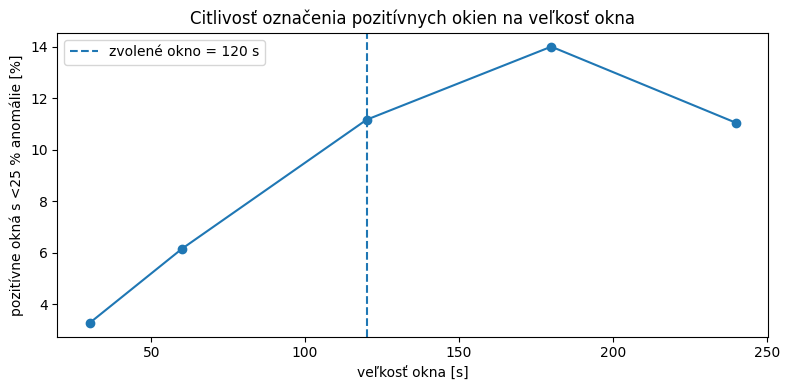

In [6]:
# Analýza voľby veľkosti okna
# Pozitívne okno je podľa make_windows označené ako anomálne, ak obsahuje
# aspoň jeden anomálny bod. Preto sledujeme, akú časť pozitívneho okna
# skutočne tvorí anomália.

CANDIDATE_WINDOW_SIZES = [30, 60, 120, 180, 240]
MIN_ANOMALY_FRACTION = 0.25

def window_label_diagnostics(df, label_col, window_sizes, stride):
    rows = []
    labels = df[label_col].to_numpy()
    n = len(labels)

    for window_size in window_sizes:
        fractions = []
        for start in range(0, n - window_size + 1, stride):
            frac = labels[start:start + window_size].mean()
            if frac > 0:
                fractions.append(frac)

        fractions = np.asarray(fractions, dtype=float)
        rows.append({
            "window_size_s": window_size,
            "n_windows": max(0, (n - window_size) // stride + 1),
            "positive_windows": len(fractions),
            "positive_share": len(fractions) / max(1, max(0, (n - window_size) // stride + 1)),
            "median_anomaly_fraction_positive": np.median(fractions) if len(fractions) else np.nan,
            "mean_anomaly_fraction_positive": np.mean(fractions) if len(fractions) else np.nan,
            "positive_windows_lt_25pct_anomaly": np.mean(fractions < MIN_ANOMALY_FRACTION) if len(fractions) else np.nan,
        })
    return pd.DataFrame(rows)

# Diagnostika naprieč všetkými anomálnymi experimentmi.
diagnostic_frames = []
for df in experiments:
    d = window_label_diagnostics(df, LABEL_COL, CANDIDATE_WINDOW_SIZES, WINDOW_STRIDE)
    d["experiment_id"] = df["experiment_id"].iloc[0]
    diagnostic_frames.append(d)

window_diagnostics_by_exp = pd.concat(diagnostic_frames, ignore_index=True)
window_diagnostics = (
    window_diagnostics_by_exp.groupby("window_size_s", as_index=False)
    .agg({
        "n_windows": "sum",
        "positive_windows": "sum",
        "positive_share": "mean",
        "median_anomaly_fraction_positive": "median",
        "mean_anomaly_fraction_positive": "mean",
        "positive_windows_lt_25pct_anomaly": "mean",
    })
)

print("Diagnostika voľby veľkosti okna:")
display(window_diagnostics.round(3))

plt.figure(figsize=(8, 4))
plt.plot(window_diagnostics["window_size_s"],
         100 * window_diagnostics["positive_windows_lt_25pct_anomaly"],
         marker="o")
plt.axvline(WINDOW_SIZE, linestyle="--", label=f"zvolené okno = {WINDOW_SIZE} s")
plt.xlabel("veľkosť okna [s]")
plt.ylabel("pozitívne okná s <25 % anomálie [%]")
plt.title("Citlivosť označenia pozitívnych okien na veľkosť okna")
plt.legend()
plt.tight_layout()
plt.show()


In [7]:
from sklearn.preprocessing import RobustScaler

assert anomaly_free_df is not None, "Chýba anomaly-free.csv — priprav referenčné 'čisté' dáta."

X_train, y_train, _ = make_windows(anomaly_free_df, FEATURE_COLS, LABEL_COL, WINDOW_SIZE, WINDOW_STRIDE)
X_test, y_test, test_ids = build_dataset(experiments, FEATURE_COLS, LABEL_COL, WINDOW_SIZE, WINDOW_STRIDE)


scaler = RobustScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Train (normálna prevádzka): {X_train_s.shape}")
print(f"Test (s anomáliami): {X_test_s.shape}, podiel anomálií: {y_test.mean():.2%}")


Train (normálna prevádzka): (1857, 960)
Test (s anomáliami): (6697, 960), podiel anomálií: 50.66%


In [8]:
#baseline model

from sklearn.ensemble import IsolationForest
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

iso = IsolationForest(n_estimators=200, contamination="auto", random_state=RANDOM_STATE)
iso.fit(X_train_s)

y_pred_iso = (iso.predict(X_test_s) == -1).astype(int)

def report(y_true, y_pred, name):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    far = fp / (fp + tn) if (fp + tn) else 0.0   # False Alarm Rate
    mar = fn / (fn + tp) if (fn + tp) else 0.0   # Missing Alarm Rate
    print(f"--- {name} ---")
    print(f"F1        : {f1_score(y_true, y_pred):.3f}")
    print(f"Precision : {precision_score(y_true, y_pred):.3f}")
    print(f"Recall    : {recall_score(y_true, y_pred):.3f}")
    print(f"FAR       : {far:.2%}")
    print(f"MAR       : {mar:.2%}")

report(y_test, y_pred_iso, "Isolation Forest")


--- Isolation Forest ---
F1        : 0.672
Precision : 0.513
Recall    : 0.974
FAR       : 94.92%
MAR       : 2.62%


In [9]:
#autoencoder

from sklearn.neural_network import MLPRegressor

n_features = X_train_s.shape[1]
bottleneck = max(4, n_features // 8)

ae = MLPRegressor(
    hidden_layer_sizes=(64, bottleneck, 64),
    activation="relu",
    max_iter=500,
    random_state=RANDOM_STATE,
)
ae.fit(X_train_s, X_train_s) 

def reconstruction_error(model, X):
    X_rec = model.predict(X)
    return np.mean((X - X_rec) ** 2, axis=1)

train_errors = reconstruction_error(ae, X_train_s)
test_errors = reconstruction_error(ae, X_test_s)

threshold = np.percentile(train_errors, 99)
y_pred_ae = (test_errors > threshold).astype(int)

report(y_test, y_pred_ae, "Autoencoder (rekonštrukčná chyba)")


--- Autoencoder (rekonštrukčná chyba) ---
F1        : 0.627
Precision : 0.523
Recall    : 0.782
FAR       : 73.27%
MAR       : 21.84%


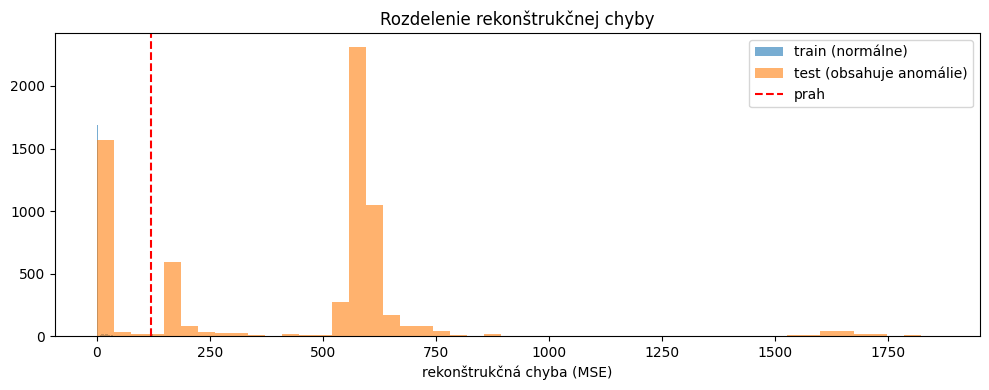

In [10]:
plt.figure(figsize=(10, 4))
plt.hist(train_errors, bins=50, alpha=0.6, label="train (normálne)")
plt.hist(test_errors, bins=50, alpha=0.6, label="test (obsahuje anomálie)")
plt.axvline(threshold, color="red", linestyle="--", label="prah")
plt.legend(); plt.xlabel("rekonštrukčná chyba (MSE)"); plt.title("Rozdelenie rekonštrukčnej chyby")
plt.tight_layout(); plt.show()


In [11]:
#kalibracia prahov

def leading_normal_segment(df: pd.DataFrame, label_col: str) -> pd.DataFrame:
    """Vráti úsek dát pred prvým výskytom anomálie (label == 1). Ak anomália nie je, vráti celý df."""
    anomaly_idx = df.index[df[label_col] == 1]
    if len(anomaly_idx) == 0:
        return df
    return df.loc[df.index < anomaly_idx[0]]

leading_segments = [leading_normal_segment(df, LABEL_COL) for df in experiments]
leading_segments = [d for d in leading_segments if len(d) >= WINDOW_SIZE]

X_calib, y_calib, calib_ids = build_dataset(leading_segments, FEATURE_COLS, LABEL_COL, WINDOW_SIZE, WINDOW_STRIDE)
assert y_calib.sum() == 0, "Kalibračné okná by nemali obsahovať žiadnu anomáliu."

X_calib_s = scaler.transform(X_calib)
calib_errors = reconstruction_error(ae, X_calib_s)

print(f"Kalibračná množina (úvodné normálne úseky z {len(leading_segments)} experimentov): {X_calib.shape}")
print(f"Priemerná chyba na anomaly-free: {train_errors.mean():.2f} | priemerná chyba na kalibračnej množine: {calib_errors.mean():.2f}")


Kalibračná množina (úvodné normálne úseky z 33 experimentov): (2989, 960)
Priemerná chyba na anomaly-free: 3.58 | priemerná chyba na kalibračnej množine: 379.61


In [12]:
old_threshold = threshold

combined_normal_errors = np.concatenate([train_errors, calib_errors])
threshold = np.percentile(combined_normal_errors, 99)

y_pred_ae_old = (test_errors > old_threshold).astype(int)
y_pred_ae = (test_errors > threshold).astype(int)

print(f"Starý prah (len anomaly-free): {old_threshold:.2f}")
print(f"Nový prah (anomaly-free + kalibračné úseky): {threshold:.2f}\n")

report(y_test, y_pred_ae_old, "Autoencoder — PÔVODNÝ prah")
print()
report(y_test, y_pred_ae, "Autoencoder — OPRAVENÝ prah (RobustScaler + kalibrácia z experimentov)")


Starý prah (len anomaly-free): 120.95
Nový prah (anomaly-free + kalibračné úseky): 686.79

--- Autoencoder — PÔVODNÝ prah ---
F1        : 0.627
Precision : 0.523
Recall    : 0.782
FAR       : 73.27%
MAR       : 21.84%

--- Autoencoder — OPRAVENÝ prah (RobustScaler + kalibrácia z experimentov) ---
F1        : 0.159
Precision : 0.761
Recall    : 0.089
FAR       : 2.88%
MAR       : 91.10%


In [13]:
#lokalne prahy
MIN_CALIB_WINDOWS = 10   

calib_ids_arr = np.array(calib_ids)
global_fallback_threshold = threshold   

thresholds_by_exp = {}
n_local = 0
for exp_id in sorted(set(test_ids)):
    local_errors = calib_errors[calib_ids_arr == exp_id]
    if len(local_errors) >= MIN_CALIB_WINDOWS:
        thresholds_by_exp[exp_id] = np.percentile(local_errors, 99)
        n_local += 1
    else:
        thresholds_by_exp[exp_id] = global_fallback_threshold

print(f"Lokálny prah použitý pre {n_local}/{len(thresholds_by_exp)} experimentov "
      f"(zvyšné majú príliš krátky pokojný úsek, použili globálny prah ako zálohu).")

y_pred_ae_global = y_pred_ae   
y_pred_ae_local = np.array([
    test_errors[i] > thresholds_by_exp[test_ids[i]]
    for i in range(len(test_errors))
]).astype(int)

report(y_test, y_pred_ae_global, "Autoencoder — globálny prah")
print()
report(y_test, y_pred_ae_local, "Autoencoder — per-experiment (lokálny) prah")

y_pred_ae = y_pred_ae_local


Lokálny prah použitý pre 33/34 experimentov (zvyšné majú príliš krátky pokojný úsek, použili globálny prah ako zálohu).
--- Autoencoder — globálny prah ---
F1        : 0.159
Precision : 0.761
Recall    : 0.089
FAR       : 2.88%
MAR       : 91.10%

--- Autoencoder — per-experiment (lokálny) prah ---
F1        : 0.610
Precision : 0.906
Recall    : 0.460
FAR       : 4.87%
MAR       : 54.02%


ROC-AUC na surovej chybe (naprieč experimentmi zliata):        0.602
ROC-AUC na normalizovanej chybe (porovnateľná škála):          0.763


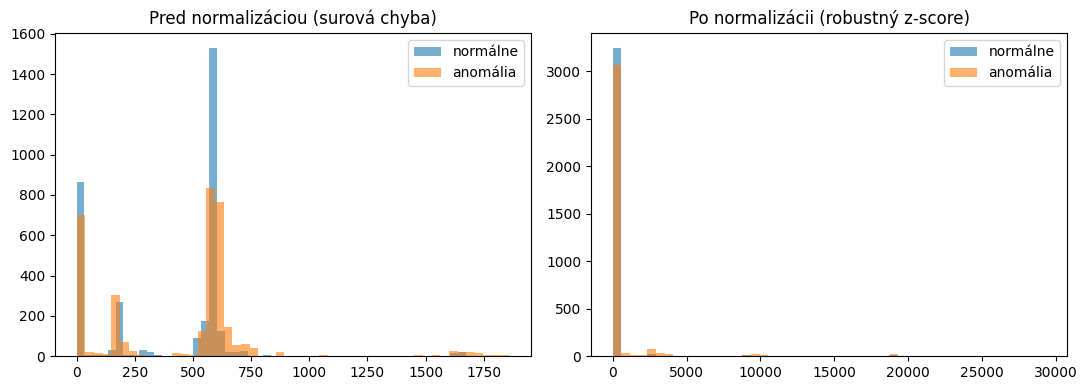

Naivný prah (99. percentil z poolnutých hodnôt): 6.93
Robustný prah (medián per-experiment 99. percentilov): 1.52

--- Autoencoder: normalizované, NAIVNÝ pooled prah ---
F1        : 0.411
Precision : 0.893
Recall    : 0.267
FAR       : 3.30%
MAR       : 73.30%

--- Autoencoder: per-experiment absolútny prah ---
F1        : 0.610
Precision : 0.906
Recall    : 0.460
FAR       : 4.87%
MAR       : 54.02%

--- Autoencoder: normalizované, ROBUSTNÝ (medián) prah ---
F1        : 0.669
Precision : 0.848
Recall    : 0.553
FAR       : 10.20%
MAR       : 44.74%


In [14]:
#normalizacia autoencodera

from sklearn.metrics import roc_auc_score

fallback_median, fallback_iqr = np.median(train_errors), np.percentile(train_errors, 75) - np.percentile(train_errors, 25)
fallback_iqr = max(fallback_iqr, 1e-6)

baseline_stats = {}
for exp_id in sorted(set(test_ids)):
    local_errors = calib_errors[calib_ids_arr == exp_id]
    if len(local_errors) >= MIN_CALIB_WINDOWS:
        med = np.median(local_errors)
        iqr = np.percentile(local_errors, 75) - np.percentile(local_errors, 25)
        baseline_stats[exp_id] = (med, max(iqr, 1e-6))
    else:
        baseline_stats[exp_id] = (fallback_median, fallback_iqr)

def normalize(errors, ids):
    return np.array([
        (errors[i] - baseline_stats[ids[i]][0]) / baseline_stats[ids[i]][1]
        for i in range(len(errors))
    ])

normalized_test_errors = normalize(test_errors, test_ids)
normalized_calib_errors = normalize(calib_errors, calib_ids)

auc_raw = roc_auc_score(y_test, test_errors)
auc_normalized = roc_auc_score(y_test, normalized_test_errors)
print(f"ROC-AUC na surovej chybe (naprieč experimentmi zliata):        {auc_raw:.3f}")
print(f"ROC-AUC na normalizovanej chybe (porovnateľná škála):          {auc_normalized:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(test_errors[y_test == 0], bins=50, alpha=0.6, label="normálne")
axes[0].hist(test_errors[y_test == 1], bins=50, alpha=0.6, label="anomália")
axes[0].set_title("Pred normalizáciou (surová chyba)"); axes[0].legend()
axes[1].hist(normalized_test_errors[y_test == 0], bins=50, alpha=0.6, label="normálne")
axes[1].hist(normalized_test_errors[y_test == 1], bins=50, alpha=0.6, label="anomália")
axes[1].set_title("Po normalizácii (robustný z-score)"); axes[1].legend()
plt.tight_layout(); plt.show()


per_exp_p99 = []
for exp_id in sorted(set(test_ids)):
    local_norm = normalized_calib_errors[calib_ids_arr == exp_id]
    if len(local_norm) >= MIN_CALIB_WINDOWS:
        per_exp_p99.append(np.percentile(local_norm, 99))

normalized_threshold_pooled = np.percentile(normalized_calib_errors, 99)   
normalized_threshold = np.median(per_exp_p99)                              

y_pred_ae_normalized_pooled = (normalized_test_errors > normalized_threshold_pooled).astype(int)
y_pred_ae_normalized = (normalized_test_errors > normalized_threshold).astype(int)

print(f"Naivný prah (99. percentil z poolnutých hodnôt): {normalized_threshold_pooled:.2f}")
print(f"Robustný prah (medián per-experiment 99. percentilov): {normalized_threshold:.2f}\n")
report(y_test, y_pred_ae_normalized_pooled, "Autoencoder: normalizované, NAIVNÝ pooled prah")
print()
report(y_test, y_pred_ae_local, "Autoencoder: per-experiment absolútny prah")
print()
report(y_test, y_pred_ae_normalized, "Autoencoder: normalizované, ROBUSTNÝ (medián) prah")

y_pred_ae = y_pred_ae_normalized


   percentil      prah        F1  precision    recall
0       90.0  1.009505  0.690488   0.801402  0.606543
1       93.0  1.110431  0.689737   0.818035  0.596228
2       95.0  1.209382  0.687123   0.827658  0.587386
3       97.0  1.323794  0.682935   0.835751  0.577365
4       98.0  1.337865  0.682382   0.837189  0.575892
5       99.0  1.521170  0.669045   0.847649  0.552608
6       99.5  1.576787  0.661749   0.849423  0.541998

Najlepší percentil v tomto porovnaní: 90.0 (prah=1.01, F1=0.690)


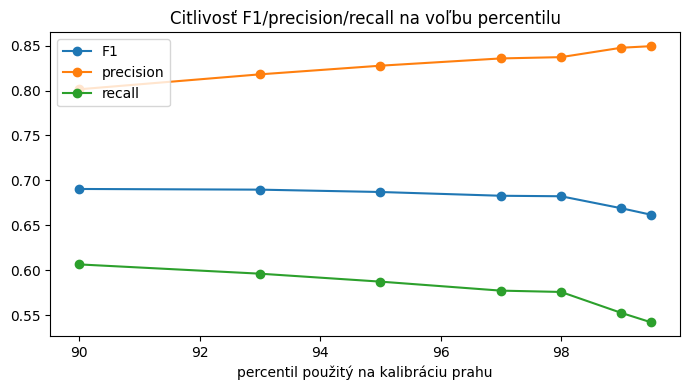

In [15]:
#testovanie percentilov

candidate_percentiles = [90, 93, 95, 97, 98, 99, 99.5]
sweep_rows = []
for p in candidate_percentiles:
    per_exp_p = []
    for exp_id in sorted(set(test_ids)):
        local_norm = normalized_calib_errors[calib_ids_arr == exp_id]
        if len(local_norm) >= MIN_CALIB_WINDOWS:
            per_exp_p.append(np.percentile(local_norm, p))
    thr = np.median(per_exp_p)
    y_pred_p = (normalized_test_errors > thr).astype(int)
    sweep_rows.append({
        "percentil": p, "prah": thr,
        "F1": f1_score(y_test, y_pred_p, zero_division=0),
        "precision": precision_score(y_test, y_pred_p, zero_division=0),
        "recall": recall_score(y_test, y_pred_p, zero_division=0),
    })

sweep_df = pd.DataFrame(sweep_rows)
print(sweep_df)

best_row = sweep_df.loc[sweep_df["F1"].idxmax()]
print(f"\nNajlepší percentil v tomto porovnaní: {best_row['percentil']} (prah={best_row['prah']:.2f}, F1={best_row['F1']:.3f})")

plt.figure(figsize=(7, 4))
plt.plot(sweep_df["percentil"], sweep_df["F1"], marker="o", label="F1")
plt.plot(sweep_df["percentil"], sweep_df["precision"], marker="o", label="precision")
plt.plot(sweep_df["percentil"], sweep_df["recall"], marker="o", label="recall")
plt.xlabel("percentil použitý na kalibráciu prahu"); plt.legend(); plt.title("Citlivosť F1/precision/recall na voľbu percentilu")
plt.tight_layout(); plt.show()


In [16]:
FINAL_PERCENTILE = 90

final_per_exp_p = []
for exp_id in sorted(set(test_ids)):
    local_norm = normalized_calib_errors[calib_ids_arr == exp_id]
    if len(local_norm) >= MIN_CALIB_WINDOWS:
        final_per_exp_p.append(np.percentile(local_norm, FINAL_PERCENTILE))

normalized_threshold = np.median(final_per_exp_p)
y_pred_ae_final = (normalized_test_errors > normalized_threshold).astype(int)

print(f"Finálny prah (medián {FINAL_PERCENTILE}. percentilov naprieč experimentmi): {normalized_threshold:.2f}\n")
report(y_test, y_pred_ae, "Autoencoder — 6d, percentil 99 (predchádzajúca voľba)")
print()
report(y_test, y_pred_ae_final, f"Autoencoder — 6d FINÁLNY, percentil {FINAL_PERCENTILE}")

y_pred_ae = y_pred_ae_final


Finálny prah (medián 90. percentilov naprieč experimentmi): 1.01

--- Autoencoder — 6d, percentil 99 (predchádzajúca voľba) ---
F1        : 0.669
Precision : 0.848
Recall    : 0.553
FAR       : 10.20%
MAR       : 44.74%

--- Autoencoder — 6d FINÁLNY, percentil 90 ---
F1        : 0.690
Precision : 0.801
Recall    : 0.607
FAR       : 15.44%
MAR       : 39.35%


'Oracle' prah s najlepším F1 na normalizovanom skóre: 0.40 (F1=0.708, precision=0.707, recall=0.709)


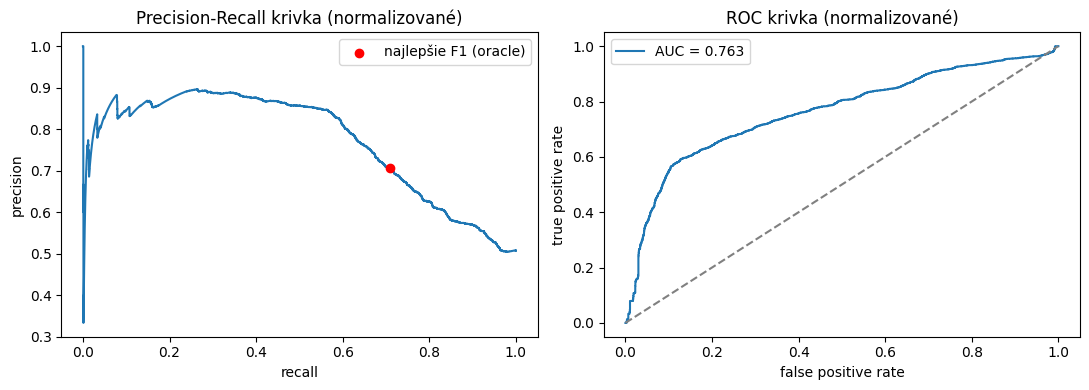

In [17]:
#PR a ROC krivky po normalizácii


from sklearn.metrics import precision_recall_curve, roc_curve, auc

precisions, recalls, pr_thresholds = precision_recall_curve(y_test, normalized_test_errors)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)
best_idx = np.argmax(f1_scores[:-1])
best_threshold_oracle = pr_thresholds[best_idx]

print(f"'Oracle' prah s najlepším F1 na normalizovanom skóre: {best_threshold_oracle:.2f} "
      f"(F1={f1_scores[best_idx]:.3f}, precision={precisions[best_idx]:.3f}, recall={recalls[best_idx]:.3f})")

fpr, tpr, _ = roc_curve(y_test, normalized_test_errors)
roc_auc = roc_auc_score(y_test, normalized_test_errors)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(recalls, precisions)
axes[0].scatter([recalls[best_idx]], [precisions[best_idx]], color="red", zorder=5, label="najlepšie F1 (oracle)")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision-Recall krivka (normalizované)")
axes[0].legend()

axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC krivka (normalizované)")
axes[1].legend()
plt.tight_layout(); plt.show()


In [18]:
rows = []
test_ids_arr = np.array(test_ids)
for exp_id in sorted(set(test_ids)):
    mask = test_ids_arr == exp_id
    y_true_e = y_test[mask]
    y_pred_e = y_pred_ae[mask]
    if y_true_e.sum() == 0 and y_pred_e.sum() == 0:
        f1_e = np.nan
    else:
        f1_e = f1_score(y_true_e, y_pred_e, zero_division=0)
    far_e = y_pred_e[y_true_e == 0].mean() if (y_true_e == 0).any() else np.nan
    mar_e = 1 - recall_score(y_true_e, y_pred_e, zero_division=0) if y_true_e.sum() else np.nan
    rows.append({"experiment_id": exp_id, "n_okien": mask.sum(), "podiel_anomalii": y_true_e.mean(),
                 "F1": f1_e, "FAR": far_e, "MAR": mar_e})

per_exp_df = pd.DataFrame(rows).sort_values("F1")
per_exp_df


,experiment_id,n_okien,podiel_anomalii,F1,FAR,MAR
15,valve1/1,206,0.504854,0.000000,0.088235,1.000000
11,other/22,192,0.479167,0.000000,0.000000,1.000000
33,valve2/3,176,0.494318,0.000000,0.112360,1.000000
31,valve2/1,189,0.476190,0.095238,0.101010,0.944444
23,valve1/3,206,0.509709,0.122137,0.178218,0.923810
6,other/17,206,0.504854,0.347305,0.333333,0.721154
26,valve1/6,207,0.507246,0.372093,0.000000,0.771429
24,valve1/4,196,0.479592,0.389831,0.009804,0.755319
8,other/19,242,0.586777,0.434343,0.130000,0.697183
22,valve1/2,192,0.473958,0.472973,0.217822,0.615385


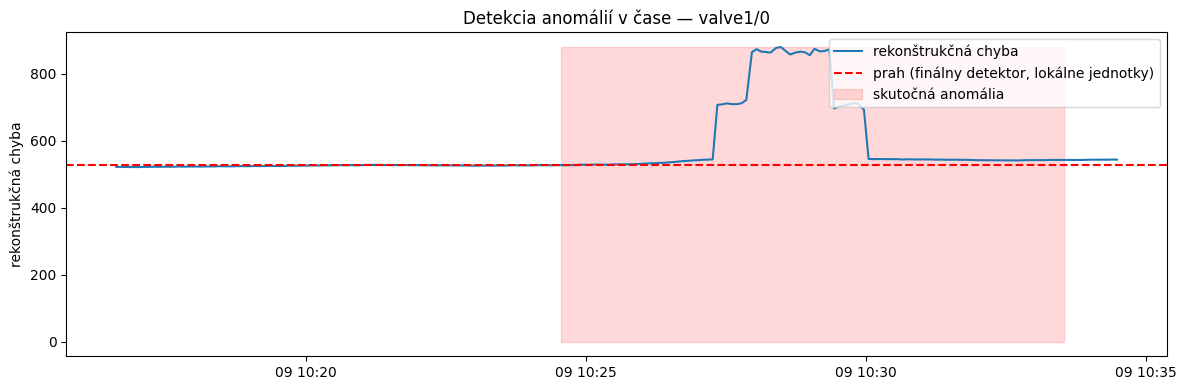

In [19]:
#vizualizácia v čase


target_exp = experiments[0]
target_exp_id = target_exp["experiment_id"].iloc[0]
X_e, y_e, idx_e = make_windows(target_exp, FEATURE_COLS, LABEL_COL, WINDOW_SIZE, WINDOW_STRIDE)
X_e_s = scaler.transform(X_e)
err_e = reconstruction_error(ae, X_e_s)


med_e, iqr_e = baseline_stats.get(target_exp_id, (fallback_median, fallback_iqr))
local_threshold_e = med_e + normalized_threshold * iqr_e

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(idx_e, err_e, color="tab:blue", label="rekonštrukčná chyba")
ax1.axhline(local_threshold_e, color="red", linestyle="--", label="prah (finálny detektor, lokálne jednotky)")
ax1.fill_between(idx_e, 0, err_e.max(), where=(np.array(y_e) == 1), color="red", alpha=0.15, label="skutočná anomália")
ax1.set_ylabel("rekonštrukčná chyba")
ax1.set_title(f"Detekcia anomálií v čase — {target_exp['experiment_id'].iloc[0]}")
ax1.legend(loc="upper right")
plt.tight_layout(); plt.show()


In [20]:
#lokalizácia vinného senzora


def per_feature_error(model, X, window_size, n_raw_features):
    X_rec = model.predict(X)
    err = (X - X_rec) ** 2
    err = err.reshape(-1, window_size, n_raw_features)
    return err.mean(axis=1)  

feat_err = per_feature_error(ae, X_e_s, WINDOW_SIZE, len(FEATURE_COLS))
feat_err_df = pd.DataFrame(feat_err, columns=FEATURE_COLS, index=idx_e)

anomalous_points = feat_err_df[err_e > local_threshold_e]
if not anomalous_points.empty:
    top_sensor = anomalous_points.mean().sort_values(ascending=False)
    print("Priemerný príspevok senzorov k chybe počas detegovaných anomálií:")
    print(top_sensor)
else:
    print("Pre tento experiment neboli detegované žiadne anomálie nad prahom.")


Priemerný príspevok senzorov k chybe počas detegovaných anomálií:
Accelerometer2RMS      1892.479101
Volume Flow RateRMS    1040.568613
Accelerometer1RMS       792.754467
Current                 686.509095
Temperature             487.804198
Thermocouple             27.404553
Voltage                   2.702644
Pressure                  0.616280
dtype: float64


In [21]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
)

WINDOW_SIZES = [30, 60, 120, 180, 240]
FIXED_STRIDE = 5          
CALIB_PERCENTILE = 90     
MIN_CALIB_WINDOWS_SWEEP = 10 

def reconstruction_error(model, X):
    """MSE rekonštrukčná chyba pre jednotlivé okná."""
    X_rec = model.predict(X)
    return np.mean((X - X_rec) ** 2, axis=1)


def calculate_metrics(y_true, y_pred):
    """F1, precision, recall, FAR a MAR."""
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    # False Alarm Rate
    far = fp / (fp + tn) if (fp + tn) else 0.0

    # Missing Alarm Rate
    mar = fn / (fn + tp) if (fn + tp) else 0.0

    return {
        "F1": f1,
        "Precision": precision,
        "Recall": recall,
        "FAR": far,
        "MAR": mar,
    }


def run_model_for_window(window_size):
    """
    Spustí celý Autoencoder pipeline pre jednu veľkosť okna.
    """

    window_stride = FIXED_STRIDE

    print("\n" + "=" * 70)
    print(f"WINDOW SIZE = {window_size} s   (stride = {window_stride} s)")
    print("=" * 70)

   

    X_train, y_train, _ = make_windows(
        anomaly_free_df,
        FEATURE_COLS,
        LABEL_COL,
        window_size,
        window_stride,
    )

    X_test, y_test, test_ids = build_dataset(
        experiments,
        FEATURE_COLS,
        LABEL_COL,
        window_size,
        window_stride,
    )



    calib_X_parts = []
    calib_y_parts = []
    calib_ids = []

    for df in experiments:

        normal_df = leading_normal_segment(
            df,
            LABEL_COL
        )

        X_cal, y_cal, _ = make_windows(
            normal_df,
            FEATURE_COLS,
            LABEL_COL,
            window_size,
            window_stride,
        )

        if len(X_cal) > 0:
            calib_X_parts.append(X_cal)
            calib_y_parts.append(y_cal)

            calib_ids.extend(
                [df["experiment_id"].iloc[0]] * len(y_cal)
            )

    if calib_X_parts:
        X_calib = np.vstack(calib_X_parts)
        y_calib = np.concatenate(calib_y_parts)
    else:
        X_calib = np.empty(
            (0, X_train.shape[1])
        )
        y_calib = np.array([])

    assert np.sum(y_calib) == 0, (
        "Kalibračné okná obsahujú anomáliu!"
    )

    scaler = RobustScaler().fit(X_train)

    X_train_s = scaler.transform(X_train)
    X_test_s = scaler.transform(X_test)

    if len(X_calib) > 0:
        X_calib_s = scaler.transform(X_calib)
    else:
        X_calib_s = X_calib



    n_features = X_train_s.shape[1]

    bottleneck = max(
        4,
        n_features // 8
    )

    ae = MLPRegressor(
        hidden_layer_sizes=(
            64,
            bottleneck,
            64,
        ),
        activation="relu",
        max_iter=500,
        random_state=RANDOM_STATE,
    )

    ae.fit(
        X_train_s,
        X_train_s
    )

  

    train_errors = reconstruction_error(
        ae,
        X_train_s
    )

    test_errors = reconstruction_error(
        ae,
        X_test_s
    )

    calib_errors = reconstruction_error(
        ae,
        X_calib_s
    )



    baseline_stats = {}

    calib_ids_arr = np.array(calib_ids)


    if len(calib_errors) > 0:
        global_median = np.median(calib_errors)
        global_mad = np.median(np.abs(calib_errors - global_median))
        global_scale = 1.4826 * global_mad
        if global_scale < 1e-12:
            global_scale = 1.0
    else:
        global_median = 0.0
        global_scale = 1.0

    n_local_used = 0
    for exp_id in sorted(set(test_ids)):

        local_errors = calib_errors[
            calib_ids_arr == exp_id
        ]

        if len(local_errors) >= MIN_CALIB_WINDOWS_SWEEP:

            median = np.median(local_errors)
            mad = np.median(np.abs(local_errors - median))
            scale = 1.4826 * mad
            if scale < 1e-12:
                scale = 1.0

            baseline_stats[exp_id] = (median, scale)
            n_local_used += 1
        else:
            baseline_stats[exp_id] = (global_median, global_scale)

    print(f"Lokálna kalibrácia použitá pre {n_local_used}/{len(set(test_ids))} experimentov "
          f"(zvyšné mali < {MIN_CALIB_WINDOWS_SWEEP} kalibračných okien, použili globálny fallback).")



    def normalize(errors, ids):
        out = np.empty(len(errors))
        for i, (error, exp_id) in enumerate(zip(errors, ids)):
            median, scale = baseline_stats.get(exp_id, (global_median, global_scale))
            out[i] = (error - median) / scale
        return out

    normalized_test_errors = normalize(test_errors, test_ids)
    normalized_calib_errors = normalize(calib_errors, calib_ids)


    per_exp_p = []

    for exp_id in sorted(set(calib_ids)):

        local_norm = normalized_calib_errors[
            calib_ids_arr == exp_id
        ]

        if len(local_norm) >= MIN_CALIB_WINDOWS_SWEEP:
            per_exp_p.append(
                np.percentile(local_norm, CALIB_PERCENTILE)
            )

    if per_exp_p:
        threshold = np.median(per_exp_p)
    else:
        threshold = np.percentile(normalized_calib_errors, CALIB_PERCENTILE)


    y_pred = (
        normalized_test_errors
        > threshold
    ).astype(int)



    metrics = calculate_metrics(
        y_test,
        y_pred
    )

    metrics["window_size_s"] = window_size
    metrics["stride_s"] = window_stride
    metrics["threshold"] = threshold
    metrics["n_train_windows"] = len(X_train)
    metrics["n_test_windows"] = len(X_test)
    metrics["n_experiments_local_calib"] = n_local_used

    print(
        f"Train windows : {len(X_train)}"
    )

    print(
        f"Test windows  : {len(X_test)}"
    )

    print(
        f"Threshold     : {threshold:.3f}"
    )

    print(
        f"F1            : {metrics['F1']:.3f}"
    )

    print(
        f"Precision     : {metrics['Precision']:.3f}"
    )

    print(
        f"Recall        : {metrics['Recall']:.3f}"
    )

    print(
        f"FAR           : {metrics['FAR']:.2%}"
    )

    print(
        f"MAR           : {metrics['MAR']:.2%}"
    )

    return metrics


results = []

for window_size in WINDOW_SIZES:

    result = run_model_for_window(
        window_size
    )

    results.append(result)

results_df = pd.DataFrame(
    results
)

results_df = results_df[
    [
        "window_size_s",
        "stride_s",
        "F1",
        "Precision",
        "Recall",
        "FAR",
        "MAR",
        "threshold",
        "n_train_windows",
        "n_test_windows",
        "n_experiments_local_calib",
    ]
].sort_values(
    "window_size_s"
)

print("\n")
print("=" * 90)
print("POROVNANIE VEĽKOSTI OKNA (opravené: percentil 90, MIN_CALIB_WINDOWS ochrana, stride škálovaný s oknom)")
print("=" * 90)

display(
    results_df.style.format({
        "F1": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "FAR": "{:.2%}",
        "MAR": "{:.2%}",
        "threshold": "{:.3f}",
    })
)



WINDOW SIZE = 30 s   (stride = 5 s)
Lokálna kalibrácia použitá pre 34/34 experimentov (zvyšné mali < 10 kalibračných okien, použili globálny fallback).
Train windows : 1875
Test windows  : 7309
Threshold     : 1.352
F1            : 0.683
Precision     : 0.701
Recall        : 0.665
FAR           : 18.02%
MAR           : 33.45%

WINDOW SIZE = 60 s   (stride = 5 s)
Lokálna kalibrácia použitá pre 34/34 experimentov (zvyšné mali < 10 kalibračných okien, použili globálny fallback).
Train windows : 1869
Test windows  : 7105
Threshold     : 1.595
F1            : 0.698
Precision     : 0.738
Recall        : 0.662
FAR           : 17.40%
MAR           : 33.82%

WINDOW SIZE = 120 s   (stride = 5 s)
Lokálna kalibrácia použitá pre 33/34 experimentov (zvyšné mali < 10 kalibračných okien, použili globálny fallback).
Train windows : 1857
Test windows  : 6697
Threshold     : 1.565
F1            : 0.690
Precision     : 0.790
Recall        : 0.612
FAR           : 16.71%
MAR           : 38.79%

WINDOW SIZE

,window_size_s,stride_s,F1,Precision,Recall,FAR,MAR,threshold,n_train_windows,n_test_windows,n_experiments_local_calib
0,30,5,0.683,0.701,0.665,18.02%,33.45%,1.352,1875,7309,34
1,60,5,0.698,0.738,0.662,17.40%,33.82%,1.595,1869,7105,34
2,120,5,0.690,0.790,0.612,16.71%,38.79%,1.565,1857,6697,33
3,180,5,0.759,0.874,0.671,13.81%,32.93%,1.410,1845,6289,33
4,240,5,0.777,0.898,0.685,13.06%,31.51%,1.092,1833,5881,33


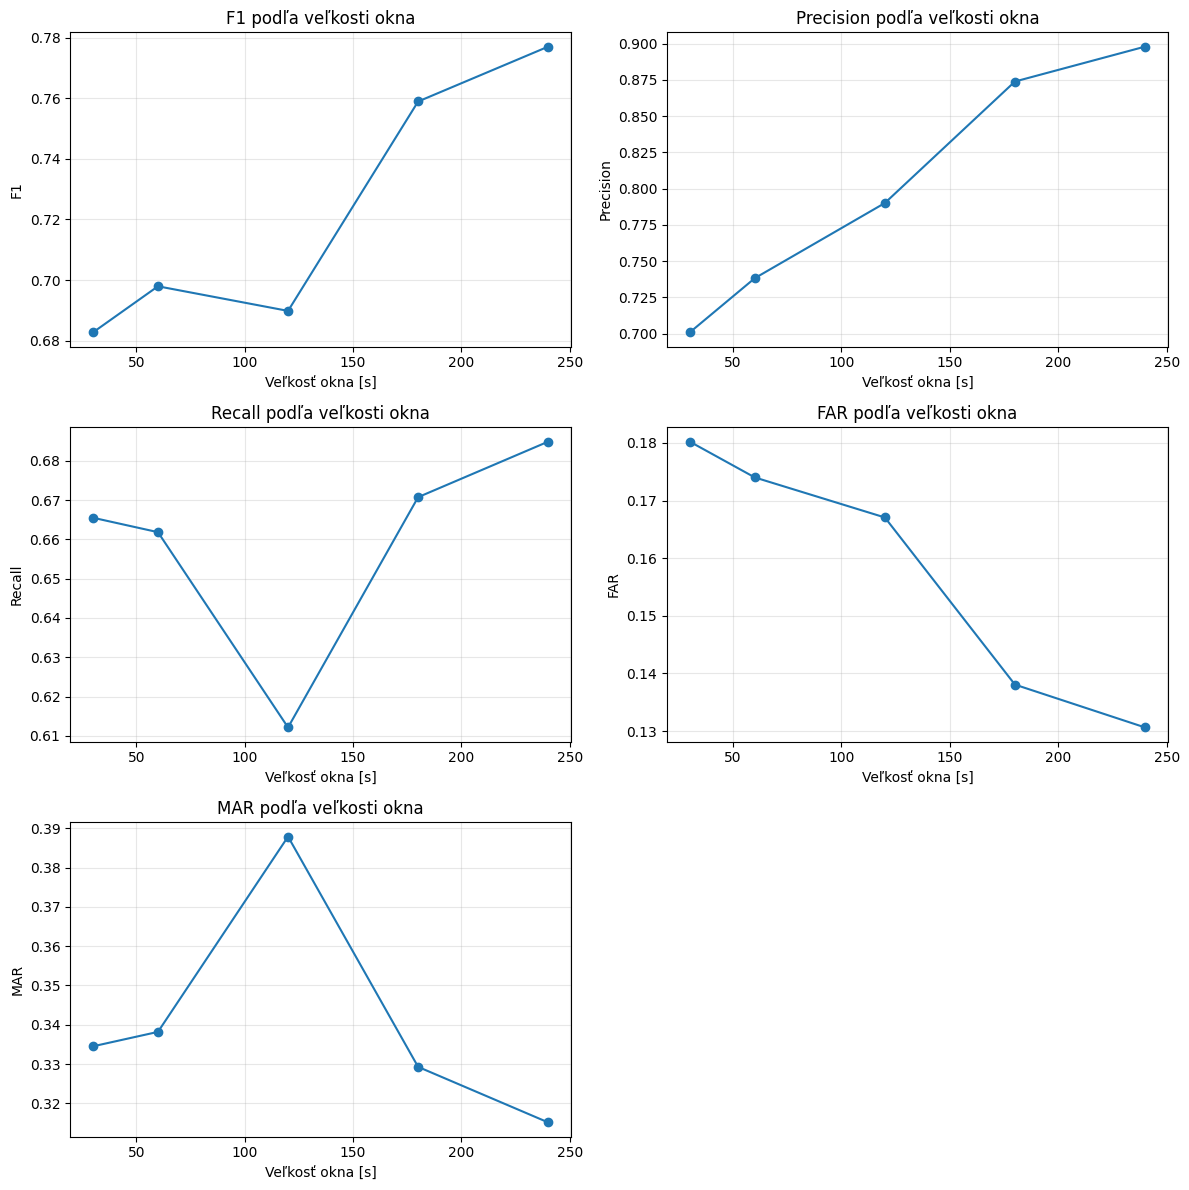

In [22]:

metrics_to_plot = [
    "F1",
    "Precision",
    "Recall",
    "FAR",
    "MAR",
]

fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 12)
)

axes = axes.flatten()

for i, metric in enumerate(metrics_to_plot):

    axes[i].plot(
        results_df["window_size_s"],
        results_df[metric],
        marker="o",
    )

    axes[i].set_xlabel(
        "Veľkosť okna [s]"
    )

    axes[i].set_ylabel(
        metric
    )

    axes[i].set_title(
        f"{metric} podľa veľkosti okna"
    )

    axes[i].grid(
        True,
        alpha=0.3
    )

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:


import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Používam zariadenie: {device}")

N_EPOCHS_SWEEP = 40   # menej epôch než pri jednorazovom CNN experimente, aby bol sweep rýchlejší


class ConvAutoencoder(nn.Module):
    def __init__(self, n_channels, bottleneck_channels=4):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(n_channels, 16, kernel_size=5, stride=2, padding=2), nn.ReLU(),
            nn.Conv1d(16, bottleneck_channels, kernel_size=5, stride=2, padding=2), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(bottleneck_channels, 16, kernel_size=5, stride=2, padding=2), nn.ReLU(),
            nn.ConvTranspose1d(16, n_channels, kernel_size=5, stride=2, padding=2),
        )

    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        if out.shape[-1] != x.shape[-1]:
            out = nn.functional.interpolate(out, size=x.shape[-1], mode="linear", align_corners=False)
        return out


def calibrate_and_threshold(train_err, calib_err, calib_ids_local, test_err, test_ids_local,
                             percentile=CALIB_PERCENTILE, min_windows=MIN_CALIB_WINDOWS_SWEEP):
    """Rovnaká logika ako v MLP sweepe vyššie, zabalená pre opakované použitie s iným modelom."""
    calib_ids_arr_local = np.array(calib_ids_local)

    if len(train_err) > 0:
        fb_med = np.median(train_err)
        fb_mad = np.median(np.abs(train_err - fb_med))
        fb_scale = max(1.4826 * fb_mad, 1e-6)
    else:
        fb_med, fb_scale = 0.0, 1.0

    stats = {}
    n_local = 0
    for exp_id in sorted(set(test_ids_local)):
        local = calib_err[calib_ids_arr_local == exp_id]
        if len(local) >= min_windows:
            med = np.median(local)
            mad = np.median(np.abs(local - med))
            stats[exp_id] = (med, max(1.4826 * mad, 1e-6))
            n_local += 1
        else:
            stats[exp_id] = (fb_med, fb_scale)

    def normalize(errors, ids):
        return np.array([(errors[i] - stats[ids[i]][0]) / stats[ids[i]][1] for i in range(len(errors))])

    norm_calib = normalize(calib_err, calib_ids_local)
    norm_test = normalize(test_err, test_ids_local)

    per_exp_p = []
    for exp_id in sorted(set(test_ids_local)):
        local_norm = norm_calib[calib_ids_arr_local == exp_id]
        if len(local_norm) >= min_windows:
            per_exp_p.append(np.percentile(local_norm, percentile))
    thr = np.median(per_exp_p) if per_exp_p else np.percentile(norm_calib, percentile)

    y_pred_local = (norm_test > thr).astype(int)
    return y_pred_local, thr, n_local


def run_cnn_model_for_window(window_size):
    window_stride = FIXED_STRIDE

    print("\n" + "=" * 70)
    print(f"CNN -- WINDOW SIZE = {window_size} s   (stride = {window_stride} s)")
    print("=" * 70)

    X_train, y_train, _ = make_windows(anomaly_free_df, FEATURE_COLS, LABEL_COL, window_size, window_stride)
    X_test, y_test, test_ids = build_dataset(experiments, FEATURE_COLS, LABEL_COL, window_size, window_stride)

    calib_X_parts, calib_y_parts, calib_ids = [], [], []
    for df in experiments:
        normal_df = leading_normal_segment(df, LABEL_COL)
        X_cal, y_cal, _ = make_windows(normal_df, FEATURE_COLS, LABEL_COL, window_size, window_stride)
        if len(X_cal) > 0:
            calib_X_parts.append(X_cal)
            calib_y_parts.append(y_cal)
            calib_ids.extend([df["experiment_id"].iloc[0]] * len(y_cal))

    X_calib = np.vstack(calib_X_parts) if calib_X_parts else np.empty((0, X_train.shape[1]))
    y_calib = np.concatenate(calib_y_parts) if calib_y_parts else np.array([])
    assert np.sum(y_calib) == 0, "Kalibračné okná obsahujú anomáliu!"

    scaler = RobustScaler().fit(X_train)
    X_train_s = scaler.transform(X_train)
    X_test_s = scaler.transform(X_test)
    X_calib_s = scaler.transform(X_calib) if len(X_calib) > 0 else X_calib

    n_channels = len(FEATURE_COLS)
    X_train_3d = X_train_s.reshape(-1, window_size, n_channels).transpose(0, 2, 1).astype(np.float32)
    X_test_3d = X_test_s.reshape(-1, window_size, n_channels).transpose(0, 2, 1).astype(np.float32)
    X_calib_3d = X_calib_s.reshape(-1, window_size, n_channels).transpose(0, 2, 1).astype(np.float32)

    torch.manual_seed(RANDOM_STATE)
    model = ConvAutoencoder(n_channels=n_channels).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train_3d)), batch_size=64, shuffle=True)

    model.train()
    for epoch in range(N_EPOCHS_SWEEP):
        for (batch,) in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            recon = model(batch)
            loss = criterion(recon, batch)
            loss.backward()
            optimizer.step()

    @torch.no_grad()
    def recon_error(X_3d, batch_size=256):
        model.eval()
        errors = []
        for i in range(0, len(X_3d), batch_size):
            batch = torch.from_numpy(X_3d[i:i + batch_size]).to(device)
            recon = model(batch)
            err = ((batch - recon) ** 2).mean(dim=(1, 2))
            errors.append(err.cpu().numpy())
        return np.concatenate(errors) if errors else np.array([])

    train_errors = recon_error(X_train_3d)
    test_errors = recon_error(X_test_3d)
    calib_errors = recon_error(X_calib_3d)

    y_pred, thr, n_local = calibrate_and_threshold(train_errors, calib_errors, calib_ids, test_errors, test_ids)

    metrics = calculate_metrics(y_test, y_pred)
    metrics["window_size_s"] = window_size
    metrics["stride_s"] = window_stride
    metrics["threshold"] = thr
    metrics["n_train_windows"] = len(X_train)
    metrics["n_test_windows"] = len(X_test)
    metrics["n_experiments_local_calib"] = n_local

    print(f"Train windows : {len(X_train)}")
    print(f"Test windows  : {len(X_test)}")
    print(f"Lokálna kalibrácia použitá pre {n_local}/{len(set(test_ids))} experimentov.")
    print(f"Threshold     : {thr:.3f}")
    print(f"F1            : {metrics['F1']:.3f}")
    print(f"Precision     : {metrics['Precision']:.3f}")
    print(f"Recall        : {metrics['Recall']:.3f}")
    print(f"FAR           : {metrics['FAR']:.2%}")
    print(f"MAR           : {metrics['MAR']:.2%}")

    return metrics


cnn_results = [run_cnn_model_for_window(ws) for ws in WINDOW_SIZES]
cnn_results_df = pd.DataFrame(cnn_results)[
    ["window_size_s", "stride_s", "F1", "Precision", "Recall", "FAR", "MAR",
     "threshold", "n_train_windows", "n_test_windows", "n_experiments_local_calib"]
].sort_values("window_size_s")

print("\n")
print("=" * 90)
print("POROVNANIE VEĽKOSTI OKNA -- CNN (Conv1D)")
print("=" * 90)
display(cnn_results_df.style.format({
    "F1": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
    "FAR": "{:.2%}", "MAR": "{:.2%}", "threshold": "{:.3f}",
}))


Používam zariadenie: cpu

CNN -- WINDOW SIZE = 30 s   (stride = 5 s)
Train windows : 1875
Test windows  : 7309
Lokálna kalibrácia použitá pre 34/34 experimentov.
Threshold     : 1.691
F1            : 0.605
Precision     : 0.655
Recall        : 0.562
FAR           : 18.78%
MAR           : 43.78%

CNN -- WINDOW SIZE = 60 s   (stride = 5 s)
Train windows : 1869
Test windows  : 7105
Lokálna kalibrácia použitá pre 34/34 experimentov.
Threshold     : 1.631
F1            : 0.647
Precision     : 0.711
Recall        : 0.593
FAR           : 17.84%
MAR           : 40.66%

CNN -- WINDOW SIZE = 120 s   (stride = 5 s)
Train windows : 1857
Test windows  : 6697
Lokálna kalibrácia použitá pre 33/34 experimentov.
Threshold     : 1.505
F1            : 0.714
Precision     : 0.791
Recall        : 0.650
FAR           : 17.65%
MAR           : 34.95%

CNN -- WINDOW SIZE = 180 s   (stride = 5 s)
Train windows : 1845
Test windows  : 6289
Lokálna kalibrácia použitá pre 33/34 experimentov.
Threshold     : 1.408
F

,window_size_s,stride_s,F1,Precision,Recall,FAR,MAR,threshold,n_train_windows,n_test_windows,n_experiments_local_calib
0,30,5,0.605,0.655,0.562,18.78%,43.78%,1.691,1875,7309,34
1,60,5,0.647,0.711,0.593,17.84%,40.66%,1.631,1869,7105,34
2,120,5,0.714,0.791,0.650,17.65%,34.95%,1.505,1857,6697,33
3,180,5,0.778,0.881,0.696,13.34%,30.41%,1.408,1845,6289,33
4,240,5,0.810,0.905,0.733,12.93%,26.74%,1.183,1833,5881,33


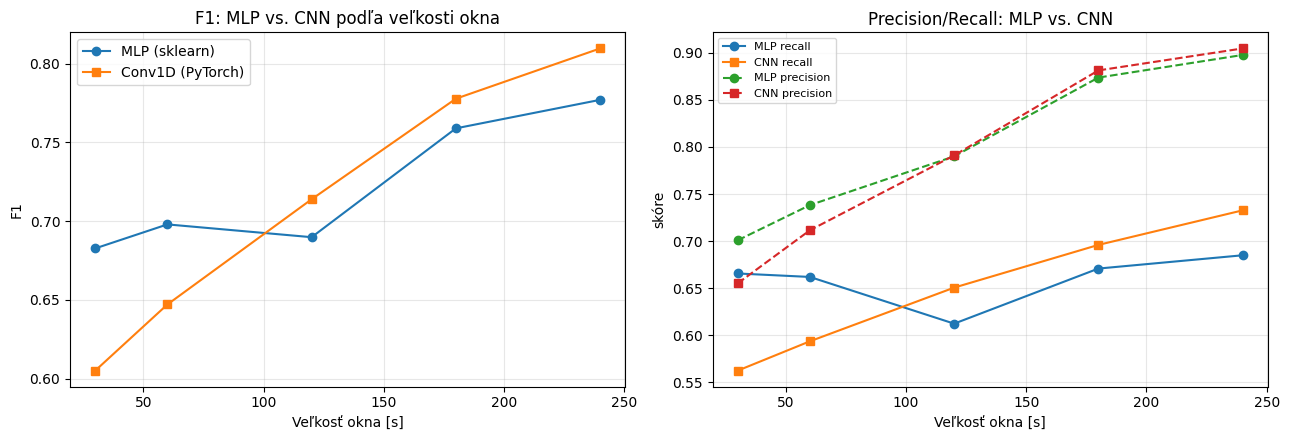

   window_size_s    F1_MLP  Precision_MLP  Recall_MLP    F1_CNN  \
0             30  0.682698       0.700817    0.665492  0.605083   
1             60  0.697926       0.738201    0.661818  0.647080   
2            120  0.689804       0.790034    0.612143  0.713893   
3            180  0.758916       0.873810    0.670725  0.777744   
4            240  0.777025       0.897865    0.684853  0.809660   

   Precision_CNN  Recall_CNN  
0       0.655031    0.562214  
1       0.711455    0.593388  
2       0.791039    0.650457  
3       0.881426    0.695887  
4       0.904794    0.732628  


In [ ]:


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(results_df["window_size_s"], results_df["F1"], marker="o", label="MLP (sklearn)")
axes[0].plot(cnn_results_df["window_size_s"], cnn_results_df["F1"], marker="s", label="Conv1D (PyTorch)")
axes[0].set_xlabel("Veľkosť okna [s]"); axes[0].set_ylabel("F1")
axes[0].set_title("F1: MLP vs. CNN podľa veľkosti okna")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(results_df["window_size_s"], results_df["Recall"], marker="o", label="MLP recall")
axes[1].plot(cnn_results_df["window_size_s"], cnn_results_df["Recall"], marker="s", label="CNN recall")
axes[1].plot(results_df["window_size_s"], results_df["Precision"], marker="o", linestyle="--", label="MLP precision")
axes[1].plot(cnn_results_df["window_size_s"], cnn_results_df["Precision"], marker="s", linestyle="--", label="CNN precision")
axes[1].set_xlabel("Veľkosť okna [s]"); axes[1].set_ylabel("skóre")
axes[1].set_title("Precision/Recall: MLP vs. CNN")
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

comparison_df = results_df[["window_size_s", "F1", "Precision", "Recall"]].merge(
    cnn_results_df[["window_size_s", "F1", "Precision", "Recall"]],
    on="window_size_s", suffixes=("_MLP", "_CNN")
)
print(comparison_df)


In [25]:
# ============================================================
# SUPERVISED CNN KLASIFIKÁTOR -- "upper bound" porovnanie
# ============================================================
# Na rozdiel od autoencodera (MLP aj CNN vyššie), ktorý sa trénuje LEN na
# normálnej prevádzke a anomáliu pozná podľa zlej rekonštrukcie, tento
# model je priamo natrénovaný na binárny label (anomaly/normal) -- teda
# POTREBUJE vidieť skutočné anomálie pri tréningu.
#
# DÔLEŽITÉ -- iný spôsob rozdelenia dát než všade vyššie:
# aby model nemohol jednoducho "zapamätať si" konkrétne experimenty,
# delíme na train/test podľa EXPERIMENTOV (nie podľa okien) -- model sa
# učí na jednej skupine experimentov a testuje sa na úplne inej skupine,
# ktorú nikdy nevidel. Preto čísla z tejto sekcie NIE SÚ priamo 1:1
# porovnateľné s tabuľkami vyššie (iný test set) -- berme to ako
# orientačný "čo by sme dosiahli, keby sme mali dosť označených
# anomálií vopred" strop, nie ako férové A/B porovnanie na rovnakých dátach.

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_EPOCHS_SUPERVISED = 30
TEST_EXPERIMENT_FRACTION = 0.3

rng = np.random.RandomState(RANDOM_STATE)
exp_order = rng.permutation(len(experiments))
n_test_exps = max(1, int(len(experiments) * TEST_EXPERIMENT_FRACTION))
test_exp_idx = set(exp_order[:n_test_exps])

train_experiments = [experiments[i] for i in range(len(experiments)) if i not in test_exp_idx]
test_experiments = [experiments[i] for i in range(len(experiments)) if i in test_exp_idx]

print(f"Tréningové experimenty: {len(train_experiments)}  |  Testovacie (nikdy nevidené): {len(test_experiments)}")
print("Testovacie experimenty:", sorted(df['experiment_id'].iloc[0] for df in test_experiments))


class ConvClassifier(nn.Module):
    """Rovnaký typ encoderu ako autoencoder vyššie, ale namiesto dekódera
    nasleduje global average pooling cez čas + lineárna vrstva -> jedno
    skóre (pravdepodobnosť anomálie)."""

    def __init__(self, n_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_channels, 16, kernel_size=5, stride=2, padding=2), nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=5, stride=2, padding=2), nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        z = self.conv(x)
        z = self.pool(z).squeeze(-1)   # (batch, 32)
        return self.fc(z).squeeze(-1)  # (batch,) -- logit


def run_supervised_cnn_for_window(window_size):
    window_stride = FIXED_STRIDE
    n_channels = len(FEATURE_COLS)

    print("\n" + "=" * 70)
    print(f"SUPERVISED CNN -- WINDOW SIZE = {window_size} s   (stride = {window_stride} s)")
    print("=" * 70)

    X_train, y_train, _ = build_dataset(train_experiments, FEATURE_COLS, LABEL_COL, window_size, window_stride)
    X_test, y_test, _ = build_dataset(test_experiments, FEATURE_COLS, LABEL_COL, window_size, window_stride)

    scaler = RobustScaler().fit(X_train)
    X_train_s = scaler.transform(X_train)
    X_test_s = scaler.transform(X_test)

    X_train_3d = X_train_s.reshape(-1, window_size, n_channels).transpose(0, 2, 1).astype(np.float32)
    X_test_3d = X_test_s.reshape(-1, window_size, n_channels).transpose(0, 2, 1).astype(np.float32)

    torch.manual_seed(RANDOM_STATE)
    model = ConvClassifier(n_channels=n_channels).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.BCEWithLogitsLoss()

    train_ds = TensorDataset(
        torch.from_numpy(X_train_3d),
        torch.from_numpy(y_train.astype(np.float32)),
    )
    train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)

    model.train()
    for epoch in range(N_EPOCHS_SUPERVISED):
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()

    @torch.no_grad()
    def predict_proba(X_3d, batch_size=256):
        model.eval()
        probs = []
        for i in range(0, len(X_3d), batch_size):
            batch = torch.from_numpy(X_3d[i:i + batch_size]).to(device)
            logits = model(batch)
            probs.append(torch.sigmoid(logits).cpu().numpy())
        return np.concatenate(probs) if probs else np.array([])

    test_probs = predict_proba(X_test_3d)
    y_pred = (test_probs > 0.5).astype(int)

    metrics = calculate_metrics(y_test, y_pred)
    metrics["window_size_s"] = window_size
    metrics["n_train_windows"] = len(X_train)
    metrics["n_test_windows"] = len(X_test)

    print(f"Train windows : {len(X_train)}  (podiel anomálií: {y_train.mean():.2%})")
    print(f"Test windows  : {len(X_test)}  (podiel anomálií: {y_test.mean():.2%})")
    print(f"F1            : {metrics['F1']:.3f}")
    print(f"Precision     : {metrics['Precision']:.3f}")
    print(f"Recall        : {metrics['Recall']:.3f}")
    print(f"FAR           : {metrics['FAR']:.2%}")
    print(f"MAR           : {metrics['MAR']:.2%}")

    return metrics


supervised_results = [run_supervised_cnn_for_window(ws) for ws in WINDOW_SIZES]
supervised_results_df = pd.DataFrame(supervised_results)[
    ["window_size_s", "F1", "Precision", "Recall", "FAR", "MAR", "n_train_windows", "n_test_windows"]
].sort_values("window_size_s")

print("\n")
print("=" * 90)
print("SUPERVISED CNN -- POROVNANIE VEĽKOSTI OKNA (iný train/test split -- orientačný strop)")
print("=" * 90)
display(supervised_results_df.style.format({
    "F1": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
    "FAR": "{:.2%}", "MAR": "{:.2%}",
}))


Tréningové experimenty: 24  |  Testovacie (nikdy nevidené): 10
Testovacie experimenty: ['other/12', 'other/15', 'other/17', 'other/18', 'other/23', 'valve1/2', 'valve1/3', 'valve1/6', 'valve1/9', 'valve2/3']

SUPERVISED CNN -- WINDOW SIZE = 30 s   (stride = 5 s)
Train windows : 5135  (podiel anomálií: 39.10%)
Test windows  : 2174  (podiel anomálií: 38.13%)
F1            : 0.588
Precision     : 0.752
Recall        : 0.483
FAR           : 9.81%
MAR           : 51.75%

SUPERVISED CNN -- WINDOW SIZE = 60 s   (stride = 5 s)
Train windows : 4991  (podiel anomálií: 42.88%)
Test windows  : 2114  (podiel anomálií: 41.86%)
F1            : 0.575
Precision     : 0.681
Recall        : 0.498
FAR           : 16.84%
MAR           : 50.17%

SUPERVISED CNN -- WINDOW SIZE = 120 s   (stride = 5 s)
Train windows : 4703  (podiel anomálií: 51.03%)
Test windows  : 1994  (podiel anomálií: 49.80%)
F1            : 0.651
Precision     : 0.621
Recall        : 0.683
FAR           : 41.26%
MAR           : 31.72%

SU

,window_size_s,F1,Precision,Recall,FAR,MAR,n_train_windows,n_test_windows
0,30,0.588,0.752,0.483,9.81%,51.75%,5135,2174
1,60,0.575,0.681,0.498,16.84%,50.17%,4991,2114
2,120,0.651,0.621,0.683,41.26%,31.72%,4703,1994
3,180,0.694,0.673,0.716,48.03%,28.43%,4415,1874
4,240,0.696,0.747,0.652,35.98%,34.77%,4127,1754


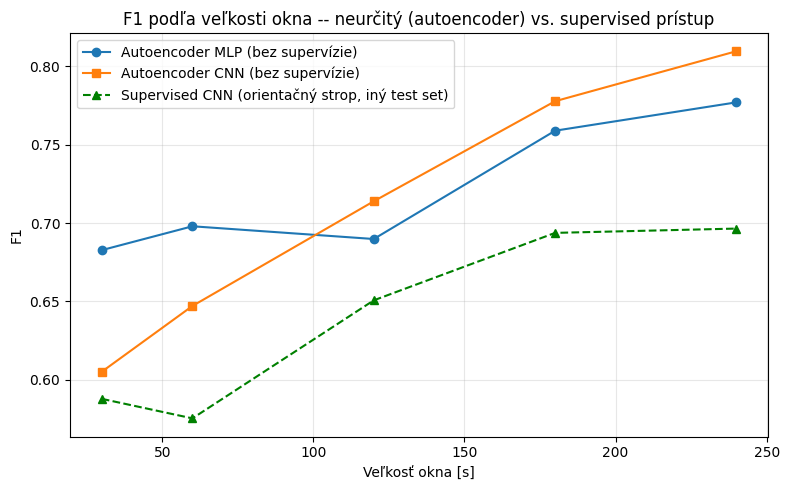

Pripomienka: supervised CNN je testovaná na inej (menšej, nikdy nevidenej) skupine experimentov
než autoencoder modely vyššie, takže rozdiel medzi čiarami je len orientačný, nie presné A/B porovnanie.


In [26]:
# ============================================================
# AUTOENCODER (MLP, CNN) vs. SUPERVISED CNN -- F1 podľa veľkosti okna
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(results_df["window_size_s"], results_df["F1"], marker="o", label="Autoencoder MLP (bez supervízie)")
plt.plot(cnn_results_df["window_size_s"], cnn_results_df["F1"], marker="s", label="Autoencoder CNN (bez supervízie)")
plt.plot(supervised_results_df["window_size_s"], supervised_results_df["F1"], marker="^", linestyle="--",
         color="green", label="Supervised CNN (orientačný strop, iný test set)")
plt.xlabel("Veľkosť okna [s]")
plt.ylabel("F1")
plt.title("F1 podľa veľkosti okna -- neurčitý (autoencoder) vs. supervised prístup")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Pripomienka: supervised CNN je testovaná na inej (menšej, nikdy nevidenej) skupine experimentov")
print("než autoencoder modely vyššie, takže rozdiel medzi čiarami je len orientačný, nie presné A/B porovnanie.")


In [27]:
# ============================================================
# LSTM AUTOENCODER (bez supervízie) -- sweep cez veľkosť okna
# ============================================================
# Okno sa NErozbaľuje do jedného dlhého vektora (ako pri MLP) a ani nemieša
# senzory konvolúciou (ako pri CNN). V každom časovom kroku vidí LSTM všetkých
# 8 senzorov naraz a postupne si buduje "pamäť" toho, ako sa signál vyvíja.
#   Encoder LSTM: prečíta celé okno -> posledný skrytý stav = zhrnutie okna
#   Bottleneck  : zhrnutie sa stlačí do malého latentného vektora (LSTM_LATENT)
#   Decoder LSTM: z latentného vektora sa snaží znovu vygenerovať celé okno
# Chyba rekonštrukcie ide cez rovnakú kalibráciu prahu ako pri ostatných modeloch.

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Používam zariadenie: {device}")

WINDOW_SIZES_LSTM = WINDOW_SIZES   # pre rýchlejší beh môžeš zúžiť, napr. [30, 120, 240]
N_EPOCHS_LSTM = 30
LSTM_MAX_STEPS = 60    # dlhšie okná sa v čase spriemerujú na max. 60 krokov (LSTM je na CPU pomalý)
LSTM_HIDDEN = 32
LSTM_LATENT = 16


def lstm_downsample(X_seq, factor):
    """X_seq: (N, T, F) -> priemer po blokoch 'factor' krokov -> (N, T//factor, F)."""
    if factor == 1:
        return X_seq
    n, t, f = X_seq.shape
    t_new = t // factor
    return X_seq[:, :t_new * factor, :].reshape(n, t_new, factor, f).mean(axis=2)


def to_sequences(X_flat_scaled, window_size, n_features, factor):
    X_seq = X_flat_scaled.reshape(-1, window_size, n_features)
    return lstm_downsample(X_seq, factor).astype(np.float32)


def get_downsample_factor(window_size):
    return max(1, int(np.ceil(window_size / LSTM_MAX_STEPS)))


class LSTMAutoencoder(nn.Module):
    def __init__(self, n_features, hidden=LSTM_HIDDEN, latent=LSTM_LATENT):
        super().__init__()
        self.encoder = nn.LSTM(n_features, hidden, batch_first=True)
        self.to_latent = nn.Linear(hidden, latent)
        self.from_latent = nn.Linear(latent, hidden)
        self.decoder = nn.LSTM(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, n_features)

    def forward(self, x):
        _, (h, _) = self.encoder(x)              # h: (1, batch, hidden)
        z = self.to_latent(h[-1])                # (batch, latent)  <- bottleneck
        d = torch.relu(self.from_latent(z))      # (batch, hidden)
        d = d.unsqueeze(1).repeat(1, x.shape[1], 1)
        dec, _ = self.decoder(d)
        return self.out(dec)                     # (batch, T, F)


def prepare_unsupervised_windows(window_size):
    """Rovnaká príprava dát ako pri MLP/CNN autoencoderi (tréning len na anomaly-free)."""
    stride = FIXED_STRIDE
    X_train, _, _ = make_windows(anomaly_free_df, FEATURE_COLS, LABEL_COL, window_size, stride)
    X_test, y_test, test_ids = build_dataset(experiments, FEATURE_COLS, LABEL_COL, window_size, stride)

    calib_parts, calib_ids = [], []
    for df in experiments:
        normal_df = leading_normal_segment(df, LABEL_COL)
        X_cal, y_cal, _ = make_windows(normal_df, FEATURE_COLS, LABEL_COL, window_size, stride)
        if len(X_cal) > 0:
            assert y_cal.sum() == 0, "Kalibračné okná obsahujú anomáliu!"
            calib_parts.append(X_cal)
            calib_ids.extend([df["experiment_id"].iloc[0]] * len(X_cal))
    X_calib = np.vstack(calib_parts) if calib_parts else np.empty((0, X_train.shape[1]))

    scaler = RobustScaler().fit(X_train)
    X_calib_s = scaler.transform(X_calib) if len(X_calib) > 0 else X_calib
    return (scaler.transform(X_train), scaler.transform(X_test), X_calib_s,
            y_test, test_ids, calib_ids, len(X_train))


def run_lstm_ae_for_window(window_size):
    n_features = len(FEATURE_COLS)
    factor = get_downsample_factor(window_size)

    print("\n" + "=" * 70)
    print(f"LSTM AUTOENCODER -- WINDOW SIZE = {window_size} s   "
          f"(časové zjemnenie x{factor} -> {window_size // factor} krokov)")
    print("=" * 70)

    X_train_s, X_test_s, X_calib_s, y_test, test_ids, calib_ids, n_train = \
        prepare_unsupervised_windows(window_size)

    X_train_seq = to_sequences(X_train_s, window_size, n_features, factor)
    X_test_seq = to_sequences(X_test_s, window_size, n_features, factor)
    X_calib_seq = to_sequences(X_calib_s, window_size, n_features, factor)

    torch.manual_seed(RANDOM_STATE)
    model = LSTMAutoencoder(n_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    loader = DataLoader(TensorDataset(torch.from_numpy(X_train_seq)), batch_size=64, shuffle=True)

    model.train()
    for epoch in range(N_EPOCHS_LSTM):
        for (batch,) in loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch), batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

    @torch.no_grad()
    def recon_error(X_seq, batch_size=256):
        model.eval()
        errs = []
        for i in range(0, len(X_seq), batch_size):
            batch = torch.from_numpy(X_seq[i:i + batch_size]).to(device)
            errs.append(((batch - model(batch)) ** 2).mean(dim=(1, 2)).cpu().numpy())
        return np.concatenate(errs) if errs else np.array([])

    train_err = recon_error(X_train_seq)
    calib_err = recon_error(X_calib_seq)
    test_err = recon_error(X_test_seq)

    y_pred, thr, n_local = calibrate_and_threshold(train_err, calib_err, calib_ids, test_err, test_ids)

    metrics = calculate_metrics(y_test, y_pred)
    metrics["window_size_s"] = window_size
    metrics["threshold"] = thr
    metrics["n_train_windows"] = n_train
    metrics["n_test_windows"] = len(X_test_s)
    metrics["n_experiments_local_calib"] = n_local

    print(f"Lokálna kalibrácia použitá pre {n_local}/{len(set(test_ids))} experimentov.")
    print(f"Threshold     : {thr:.3f}")
    print(f"F1            : {metrics['F1']:.3f}")
    print(f"Precision     : {metrics['Precision']:.3f}")
    print(f"Recall        : {metrics['Recall']:.3f}")
    print(f"FAR           : {metrics['FAR']:.2%}")
    print(f"MAR           : {metrics['MAR']:.2%}")
    return metrics


lstm_ae_results = [run_lstm_ae_for_window(ws) for ws in WINDOW_SIZES_LSTM]
lstm_ae_results_df = pd.DataFrame(lstm_ae_results)[
    ["window_size_s", "F1", "Precision", "Recall", "FAR", "MAR",
     "threshold", "n_train_windows", "n_test_windows", "n_experiments_local_calib"]
].sort_values("window_size_s")

print("\n" + "=" * 90)
print("LSTM AUTOENCODER -- POROVNANIE VEĽKOSTI OKNA")
print("=" * 90)
display(lstm_ae_results_df.style.format({
    "F1": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
    "FAR": "{:.2%}", "MAR": "{:.2%}", "threshold": "{:.3f}",
}))

Používam zariadenie: cpu

LSTM AUTOENCODER -- WINDOW SIZE = 30 s   (časové zjemnenie x1 -> 30 krokov)
Lokálna kalibrácia použitá pre 34/34 experimentov.
Threshold     : 1.634
F1            : 0.679
Precision     : 0.696
Recall        : 0.662
FAR           : 18.34%
MAR           : 33.80%

LSTM AUTOENCODER -- WINDOW SIZE = 60 s   (časové zjemnenie x1 -> 60 krokov)
Lokálna kalibrácia použitá pre 34/34 experimentov.
Threshold     : 1.836
F1            : 0.672
Precision     : 0.727
Recall        : 0.624
FAR           : 17.35%
MAR           : 37.62%

LSTM AUTOENCODER -- WINDOW SIZE = 120 s   (časové zjemnenie x2 -> 60 krokov)
Lokálna kalibrácia použitá pre 33/34 experimentov.
Threshold     : 1.521
F1            : 0.746
Precision     : 0.801
Recall        : 0.698
FAR           : 17.80%
MAR           : 30.24%

LSTM AUTOENCODER -- WINDOW SIZE = 180 s   (časové zjemnenie x3 -> 60 krokov)
Lokálna kalibrácia použitá pre 33/34 experimentov.
Threshold     : 1.364
F1            : 0.796
Precision     :

,window_size_s,F1,Precision,Recall,FAR,MAR,threshold,n_train_windows,n_test_windows,n_experiments_local_calib
0,30,0.679,0.696,0.662,18.34%,33.80%,1.634,1875,7309,34
1,60,0.672,0.727,0.624,17.35%,37.62%,1.836,1869,7105,34
2,120,0.746,0.801,0.698,17.80%,30.24%,1.521,1857,6697,33
3,180,0.796,0.881,0.725,13.92%,27.46%,1.364,1845,6289,33
4,240,0.823,0.906,0.754,13.11%,24.65%,1.055,1833,5881,33


In [28]:
# ============================================================
# SUPERVISED LSTM KLASIFIKÁTOR -- rovnaký protokol ako supervised CNN
# ============================================================
# Rovnaké rozdelenie experimentov (train_experiments / test_experiments),
# rovnaký prah 0.5, rovnaký globálny RobustScaler -- aby sa LSTM dalo férovo
# porovnať so supervised CNN. Platí tu teda aj to isté upozornenie: žiadna
# kalibrácia per experiment, takže model môže na nových behoch dávať vyšší FAR.

assert "train_experiments" in globals() and "test_experiments" in globals(), \
    "Najprv spusti bunku so supervised CNN (tá vytvára train/test rozdelenie experimentov)."


class LSTMClassifier(nn.Module):
    def __init__(self, n_features, hidden=LSTM_HIDDEN):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.fc(h[-1]).squeeze(-1)      # logit anomálie


def run_supervised_lstm_for_window(window_size):
    n_features = len(FEATURE_COLS)
    factor = get_downsample_factor(window_size)

    print("\n" + "=" * 70)
    print(f"SUPERVISED LSTM -- WINDOW SIZE = {window_size} s   "
          f"(časové zjemnenie x{factor} -> {window_size // factor} krokov)")
    print("=" * 70)

    X_train, y_train, _ = build_dataset(train_experiments, FEATURE_COLS, LABEL_COL, window_size, FIXED_STRIDE)
    X_test, y_test, _ = build_dataset(test_experiments, FEATURE_COLS, LABEL_COL, window_size, FIXED_STRIDE)

    scaler = RobustScaler().fit(X_train)
    X_train_seq = to_sequences(scaler.transform(X_train), window_size, n_features, factor)
    X_test_seq = to_sequences(scaler.transform(X_test), window_size, n_features, factor)

    torch.manual_seed(RANDOM_STATE)
    model = LSTMClassifier(n_features).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.BCEWithLogitsLoss()
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_train_seq), torch.from_numpy(y_train.astype(np.float32))),
        batch_size=64, shuffle=True,
    )

    model.train()
    for epoch in range(N_EPOCHS_LSTM):
        for batch_x, batch_y in loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

    model.eval()
    probs = []
    with torch.no_grad():
        for i in range(0, len(X_test_seq), 256):
            batch = torch.from_numpy(X_test_seq[i:i + 256]).to(device)
            probs.append(torch.sigmoid(model(batch)).cpu().numpy())
    y_pred = (np.concatenate(probs) > 0.5).astype(int)

    metrics = calculate_metrics(y_test, y_pred)
    metrics["window_size_s"] = window_size
    metrics["n_train_windows"] = len(X_train)
    metrics["n_test_windows"] = len(X_test)

    print(f"Train windows : {len(X_train)}  (podiel anomálií: {y_train.mean():.2%})")
    print(f"Test windows  : {len(X_test)}  (podiel anomálií: {y_test.mean():.2%})")
    print(f"F1            : {metrics['F1']:.3f}")
    print(f"Precision     : {metrics['Precision']:.3f}")
    print(f"Recall        : {metrics['Recall']:.3f}")
    print(f"FAR           : {metrics['FAR']:.2%}")
    print(f"MAR           : {metrics['MAR']:.2%}")
    return metrics


supervised_lstm_results = [run_supervised_lstm_for_window(ws) for ws in WINDOW_SIZES_LSTM]
supervised_lstm_results_df = pd.DataFrame(supervised_lstm_results)[
    ["window_size_s", "F1", "Precision", "Recall", "FAR", "MAR", "n_train_windows", "n_test_windows"]
].sort_values("window_size_s")

print("\n" + "=" * 90)
print("SUPERVISED LSTM -- POROVNANIE VEĽKOSTI OKNA (rovnaký train/test split ako supervised CNN)")
print("=" * 90)
display(supervised_lstm_results_df.style.format({
    "F1": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
    "FAR": "{:.2%}", "MAR": "{:.2%}",
}))


SUPERVISED LSTM -- WINDOW SIZE = 30 s   (časové zjemnenie x1 -> 30 krokov)
Train windows : 5135  (podiel anomálií: 39.10%)
Test windows  : 2174  (podiel anomálií: 38.13%)
F1            : 0.608
Precision     : 0.788
Recall        : 0.495
FAR           : 8.18%
MAR           : 50.54%

SUPERVISED LSTM -- WINDOW SIZE = 60 s   (časové zjemnenie x1 -> 60 krokov)
Train windows : 4991  (podiel anomálií: 42.88%)
Test windows  : 2114  (podiel anomálií: 41.86%)
F1            : 0.614
Precision     : 0.833
Recall        : 0.486
FAR           : 7.00%
MAR           : 51.41%

SUPERVISED LSTM -- WINDOW SIZE = 120 s   (časové zjemnenie x2 -> 60 krokov)
Train windows : 4703  (podiel anomálií: 51.03%)
Test windows  : 1994  (podiel anomálií: 49.80%)
F1            : 0.641
Precision     : 0.684
Recall        : 0.603
FAR           : 27.67%
MAR           : 39.68%

SUPERVISED LSTM -- WINDOW SIZE = 180 s   (časové zjemnenie x3 -> 60 krokov)
Train windows : 4415  (podiel anomálií: 59.09%)
Test windows  : 1874  (p

,window_size_s,F1,Precision,Recall,FAR,MAR,n_train_windows,n_test_windows
0,30,0.608,0.788,0.495,8.18%,50.54%,5135,2174
1,60,0.614,0.833,0.486,7.00%,51.41%,4991,2114
2,120,0.641,0.684,0.603,27.67%,39.68%,4703,1994
3,180,0.628,0.701,0.569,33.55%,43.15%,4415,1874
4,240,0.731,0.676,0.795,62.07%,20.52%,4127,1754


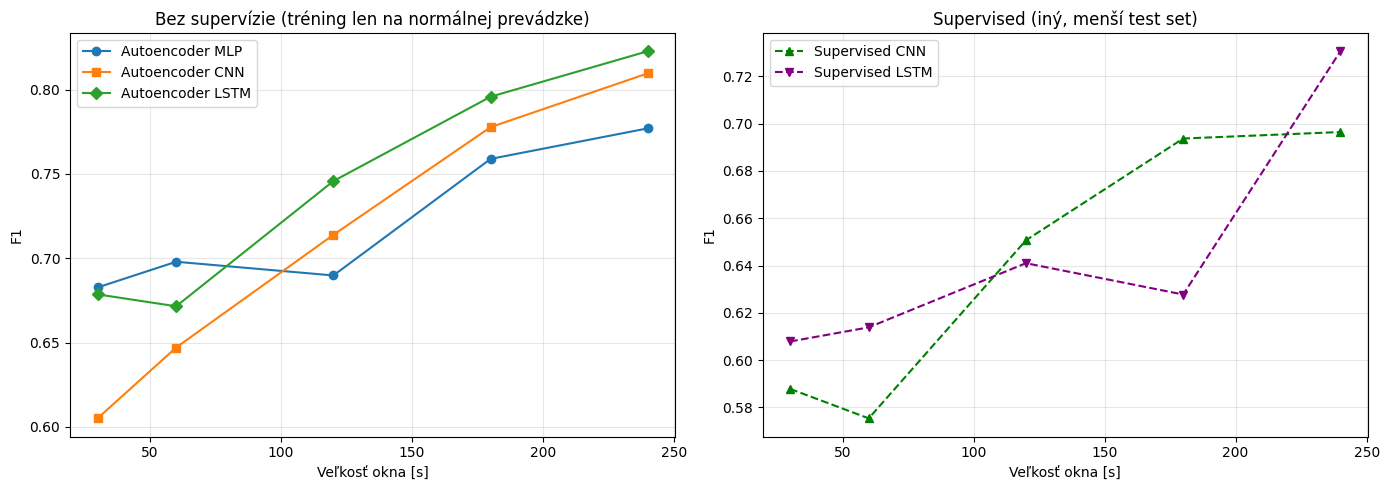

 window_size_s  F1_AE_MLP  F1_AE_CNN  F1_AE_LSTM
            30      0.683      0.605       0.679
            60      0.698      0.647       0.672
           120      0.690      0.714       0.746
           180      0.759      0.778       0.796
           240      0.777      0.810       0.823


In [29]:
# ============================================================
# SÚHRNNÉ POROVNANIE VŠETKÝCH MODELOV -- F1 podľa veľkosti okna
# ============================================================
# Ľavý panel: modely bez supervízie (rovnaký test set -- všetkých 34 experimentov)
# Pravý panel: supervised modely (rovnaký, menší test set -- 10 nevidených experimentov)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(results_df["window_size_s"], results_df["F1"], marker="o", label="Autoencoder MLP")
axes[0].plot(cnn_results_df["window_size_s"], cnn_results_df["F1"], marker="s", label="Autoencoder CNN")
axes[0].plot(lstm_ae_results_df["window_size_s"], lstm_ae_results_df["F1"], marker="D", label="Autoencoder LSTM")
axes[0].set_title("Bez supervízie (tréning len na normálnej prevádzke)")
axes[0].set_xlabel("Veľkosť okna [s]"); axes[0].set_ylabel("F1")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(supervised_results_df["window_size_s"], supervised_results_df["F1"],
             marker="^", linestyle="--", color="green", label="Supervised CNN")
axes[1].plot(supervised_lstm_results_df["window_size_s"], supervised_lstm_results_df["F1"],
             marker="v", linestyle="--", color="purple", label="Supervised LSTM")
axes[1].set_title("Supervised (iný, menší test set)")
axes[1].set_xlabel("Veľkosť okna [s]"); axes[1].set_ylabel("F1")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

summary_unsup = results_df[["window_size_s", "F1"]].rename(columns={"F1": "F1_AE_MLP"}) \
    .merge(cnn_results_df[["window_size_s", "F1"]].rename(columns={"F1": "F1_AE_CNN"}), on="window_size_s") \
    .merge(lstm_ae_results_df[["window_size_s", "F1"]].rename(columns={"F1": "F1_AE_LSTM"}), on="window_size_s")
print(summary_unsup.round(3).to_string(index=False))